# Day 10: End-to-End Tabular Machine Learning Workflow

## Project Overview

This project demonstrates a complete machine learning workflow using the Titanic dataset.

### Objectives
- Data Quality Analysis
- Exploratory Data Analysis (EDA)
- Data Preprocessing
- Model Training and Comparison
- Model Evaluation
- Error Analysis

### Technologies Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## 1. Dataset Loading

In [1]:
import sys
from pathlib import Path

# Add Day-10 project folder to Python path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from config import DATASET_PATH

# Load dataset
df = pd.read_csv(DATASET_PATH)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


## 2. Data Quality Analysis

In [2]:
# Dataset information
print("Dataset Information:")
df.info()

print("\nMissing Values:")
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

display(missing_values[missing_values["Missing Count"] > 0])

print("\nDuplicate Records:", df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB

Missing Values:


,Missing Count,Missing Percentage
age,177,19.87
embarked,2,0.22
deck,688,77.22
embark_town,2,0.22



Duplicate Records: 107

Statistical Summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
sibsp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292
embarked,889,3,S,644,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,891,3,Third,491,NaN,NaN,NaN,NaN,NaN,NaN,NaN
who,891,3,man,537,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Exploratory Data Analysis (EDA)

In [3]:
# Target distribution
print("Survival Distribution:")
display(df["survived"].value_counts())

print("\nSurvival Percentage:")
display((df["survived"].value_counts(normalize=True) * 100).round(2))

# Survival rate by gender
print("\nSurvival Rate by Gender:")
display(df.groupby("sex")["survived"].mean().mul(100).round(2))

# Survival rate by passenger class
print("\nSurvival Rate by Passenger Class:")
display(df.groupby("pclass")["survived"].mean().mul(100).round(2))

# Numerical summary
print("\nAge and Fare Summary:")
display(df[["age", "fare"]].describe())

Survival Distribution:


survived
0    549
1    342
Name: count, dtype: int64


Survival Percentage:


survived
0    61.62
1    38.38
Name: proportion, dtype: float64


Survival Rate by Gender:


sex
female    74.20
male      18.89
Name: survived, dtype: float64


Survival Rate by Passenger Class:


pclass
1    62.96
2    47.28
3    24.24
Name: survived, dtype: float64


Age and Fare Summary:


,age,fare
count,714.000000,891.000000
mean,29.699118,32.204208
std,14.526497,49.693429
min,0.420000,0.000000
25%,20.125000,7.910400
50%,28.000000,14.454200
75%,38.000000,31.000000
max,80.000000,512.329200


## 4. Data Visualization

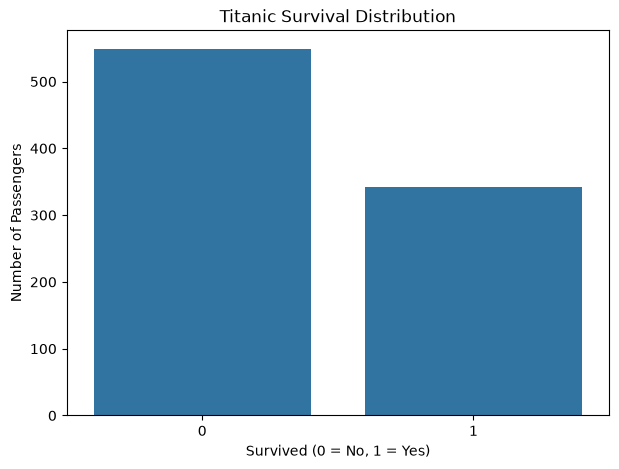

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="survived")

plt.title("Titanic Survival Distribution")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

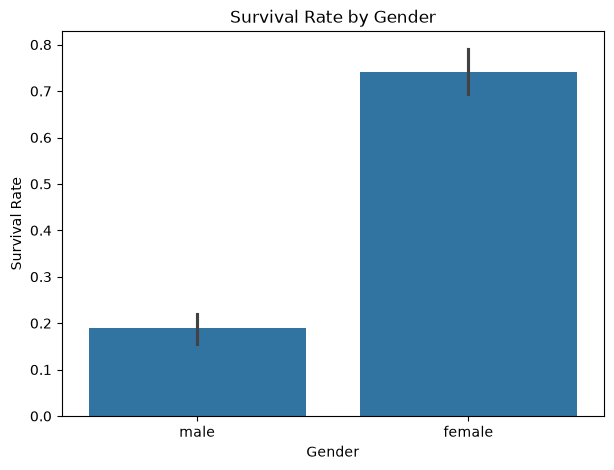

In [5]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df, x="sex", y="survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.show()

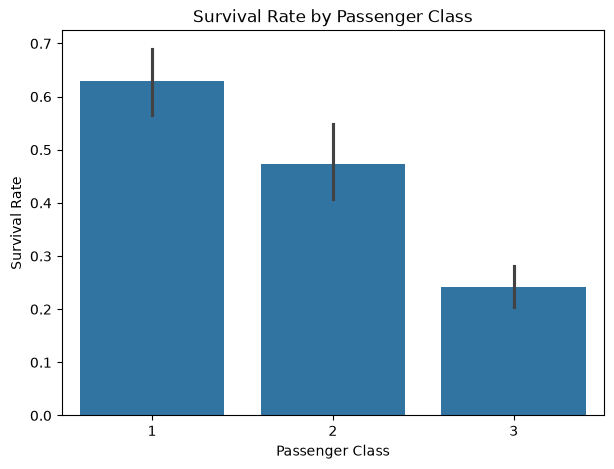

In [6]:
plt.figure(figsize=(7, 5))

sns.barplot(data=df, x="pclass", y="survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

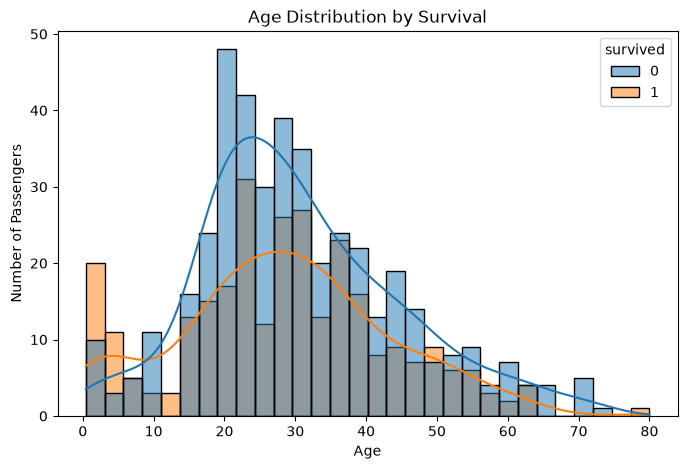

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", hue="survived", bins=30, kde=True)

plt.title("Age Distribution by Survival")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

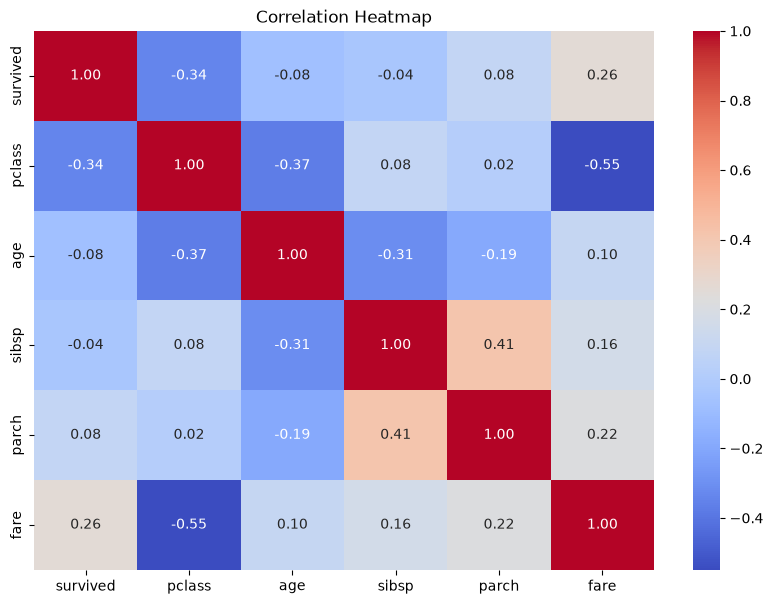

In [8]:
plt.figure(figsize=(10, 7))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

## 5. Key EDA Observations

1. Approximately 38.38% of passengers survived.
2. Female passengers had a higher survival rate than male passengers.
3. First-class passengers had a higher survival rate than third-class passengers.
4. Passenger class and gender show noticeable relationships with survival.
5. Age and fare distributions contain variations and missing values that require preprocessing.

### EDA Conclusion

Gender and passenger class appear to be important factors associated with Titanic survival. Further preprocessing and machine learning can help evaluate these patterns.

## 6. Data Preprocessing

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Remove target and leakage-related columns
excluded_columns = [
    "survived", "alive", "class", "who",
    "adult_male", "deck", "embark_town"
]

X = df.drop(columns=excluded_columns)
y = df["survived"]

# Define feature types
numerical_features = [
    "pclass", "age", "sibsp", "parch", "fare", "alone"
]

categorical_features = ["sex", "embarked"]

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Features shape: (891, 8)
Target shape: (891,)
Numerical features: ['pclass', 'age', 'sibsp', 'parch', 'fare', 'alone']
Categorical features: ['sex', 'embarked']


## 7. Train-Validation-Test Split

The dataset is divided into three subsets:

- Training Set: 60%
- Validation Set: 20%
- Testing Set: 20%

Stratified splitting maintains the survival class distribution across all subsets.

In [10]:
# First split: 80% development and 20% test
X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: 75% training and 25% validation
X_train, X_val, y_train, y_val = train_test_split(
    X_dev,
    y_dev,
    test_size=0.25,
    random_state=42,
    stratify=y_dev
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Testing Set:", X_test.shape)

print("\nClass Distribution:")
print("Training:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Validation:", y_val.value_counts(normalize=True).round(3).to_dict())
print("Testing:", y_test.value_counts(normalize=True).round(3).to_dict())

Training Set: (534, 8)
Validation Set: (178, 8)
Testing Set: (179, 8)

Class Distribution:
Training: {0: 0.616, 1: 0.384}
Validation: {0: 0.618, 1: 0.382}
Testing: {0: 0.615, 1: 0.385}


In [11]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Preprocessing completed successfully!")

print("Training processed shape:", X_train_processed.shape)
print("Validation processed shape:", X_val_processed.shape)
print("Testing processed shape:", X_test_processed.shape)

print("\nMissing values after preprocessing:")
print("Training:", np.isnan(X_train_processed.toarray() if hasattr(X_train_processed, "toarray") else X_train_processed).sum())
print("Validation:", np.isnan(X_val_processed.toarray() if hasattr(X_val_processed, "toarray") else X_val_processed).sum())
print("Testing:", np.isnan(X_test_processed.toarray() if hasattr(X_test_processed, "toarray") else X_test_processed).sum())

Preprocessing completed successfully!
Training processed shape: (534, 11)
Validation processed shape: (178, 11)
Testing processed shape: (179, 11)

Missing values after preprocessing:
Training: 0
Validation: 0
Testing: 0


## 8. Model Training and Comparison

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=5, random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=8,
        random_state=42
    )
}

results = []
trained_pipelines = {}

for model_name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)

    y_val_pred = pipeline.predict(X_val)

    results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, y_val_pred),
        "Precision": precision_score(y_val, y_val_pred),
        "Recall": recall_score(y_val, y_val_pred),
        "F1 Score": f1_score(y_val, y_val_pred)
    })

    trained_pipelines[model_name] = pipeline

print("All models trained successfully!")

All models trained successfully!


In [13]:
comparison_df = pd.DataFrame(results)

comparison_df = comparison_df.sort_values(
    by="F1 Score",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

best_model_name = comparison_df.loc[0, "Model"]
best_model = trained_pipelines[best_model_name]

print("Best Model:", best_model_name)
print("Best Validation F1 Score:",
      round(comparison_df.loc[0, "F1 Score"], 4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Random Forest,0.8427,0.8333,0.7353,0.7812
1,Decision Tree,0.8315,0.8065,0.7353,0.7692
2,Logistic Regression,0.7978,0.7667,0.6765,0.7188


Best Model: Random Forest
Best Validation F1 Score: 0.7812


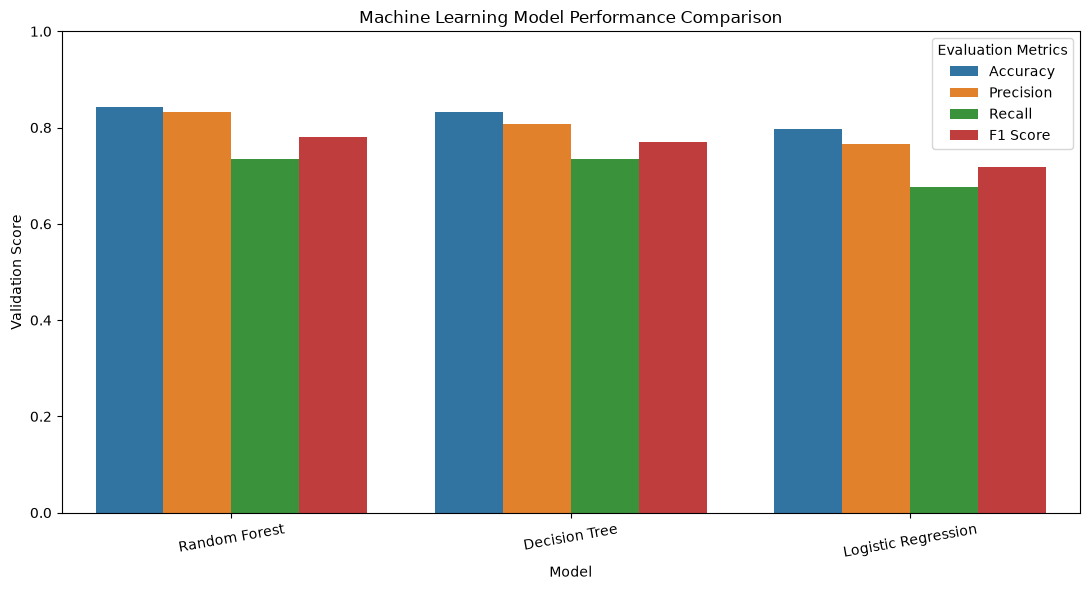

In [14]:
metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1 Score"]

comparison_long = comparison_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=comparison_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Validation Score")
plt.ylim(0, 1)
plt.xticks(rotation=10)
plt.legend(title="Evaluation Metrics")
plt.tight_layout()
plt.show()

## 9. Final Model Evaluation

In [15]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on test dataset
y_test_pred = best_model.predict(X_test)

# Calculate metrics
test_metrics = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1 Score": f1_score(y_test, y_test_pred)
}

print("FINAL TEST PERFORMANCE")
for metric, score in test_metrics.items():
    print(f"{metric}: {score:.4f} ({score * 100:.2f}%)")

FINAL TEST PERFORMANCE
Accuracy: 0.8045 (80.45%)
Precision: 0.8148 (81.48%)
Recall: 0.6377 (63.77%)
F1 Score: 0.7154 (71.54%)


In [16]:
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Not Survived", "Survived"]
))

              precision    recall  f1-score   support

Not Survived       0.80      0.91      0.85       110
    Survived       0.81      0.64      0.72        69

    accuracy                           0.80       179
   macro avg       0.81      0.77      0.78       179
weighted avg       0.81      0.80      0.80       179



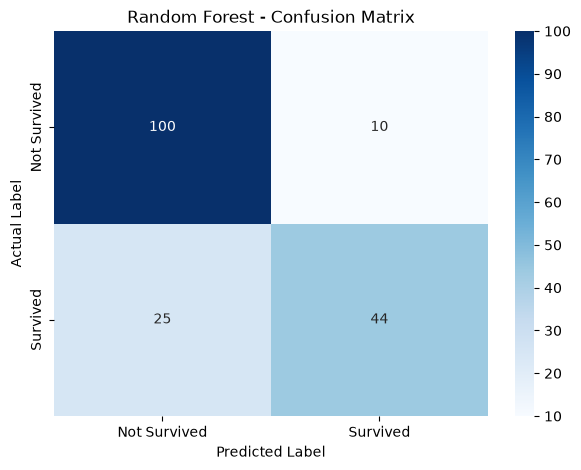

Confusion Matrix:
[[100  10]
 [ 25  44]]


In [17]:
cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Survived", "Survived"],
    yticklabels=["Not Survived", "Survived"]
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.show()

print("Confusion Matrix:")
print(cm)

### Final Evaluation Observations

In [18]:
metrics_df = pd.DataFrame(
    list(test_metrics.items()),
    columns=["Metric", "Score"]
)

metrics_df["Percentage"] = (
    metrics_df["Score"] * 100
).round(2).astype(str) + "%"

display(metrics_df)

,Metric,Score,Percentage
0,Accuracy,0.804469,80.45%
1,Precision,0.814815,81.48%
2,Recall,0.637681,63.77%
3,F1 Score,0.715447,71.54%


## 10. Error Analysis

In [19]:
# Create error analysis dataframe
error_df = X_test.copy()

error_df["Actual"] = y_test
error_df["Predicted"] = y_test_pred

error_df["Prediction_Status"] = np.select(
    [
        (error_df["Actual"] == 1) & (error_df["Predicted"] == 0),
        (error_df["Actual"] == 0) & (error_df["Predicted"] == 1)
    ],
    [
        "False Negative",
        "False Positive"
    ],
    default="Correct"
)

display(error_df.head(10))

print("\nPrediction Status:")
display(error_df["Prediction_Status"].value_counts())

,pclass,sex,age,sibsp,parch,fare,embarked,alone,Actual,Predicted,Prediction_Status
565,3,male,24.0,2,0,24.1500,S,False,0,0,Correct
160,3,male,44.0,0,1,16.1000,S,False,0,0,Correct
553,3,male,22.0,0,0,7.2250,C,True,1,0,False Negative
860,3,male,41.0,2,0,14.1083,S,False,0,0,Correct
241,3,female,NaN,1,0,15.5000,Q,False,1,1,Correct
559,3,female,36.0,1,0,17.4000,S,False,1,0,False Negative
387,2,female,36.0,0,0,13.0000,S,True,1,1,Correct
536,1,male,45.0,0,0,26.5500,S,True,0,1,False Positive
698,1,male,49.0,1,1,110.8833,C,False,0,0,Correct
99,2,male,34.0,1,0,26.0000,S,False,0,0,Correct



Prediction Status:


Prediction_Status
Correct           144
False Negative     25
False Positive     10
Name: count, dtype: int64

Prediction_Status,Correct,False Negative,False Positive
sex,,,
female,49,7,5
male,95,18,5


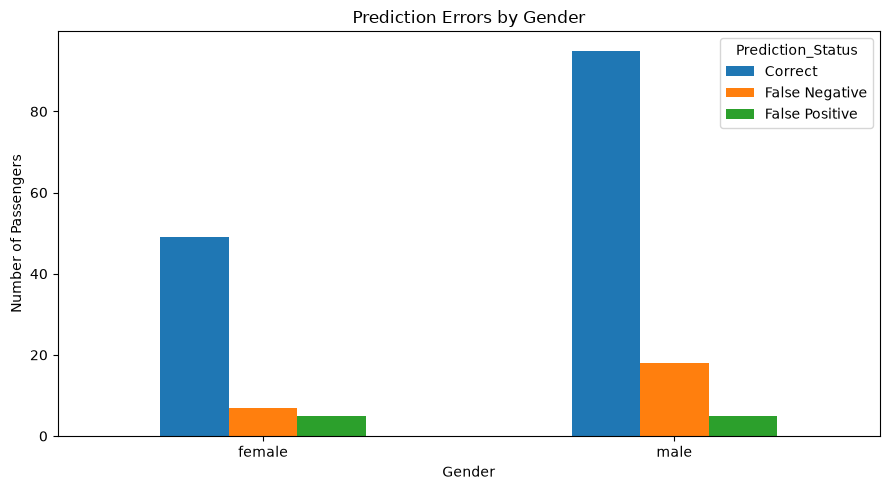

In [20]:
gender_errors = error_df.groupby(
    "sex"
)["Prediction_Status"].value_counts().unstack(fill_value=0)

display(gender_errors)

gender_errors.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Prediction Errors by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Prediction_Status,Correct,False Negative,False Positive
pclass,,,
1,34,7,4
2,30,3,1
3,80,15,5


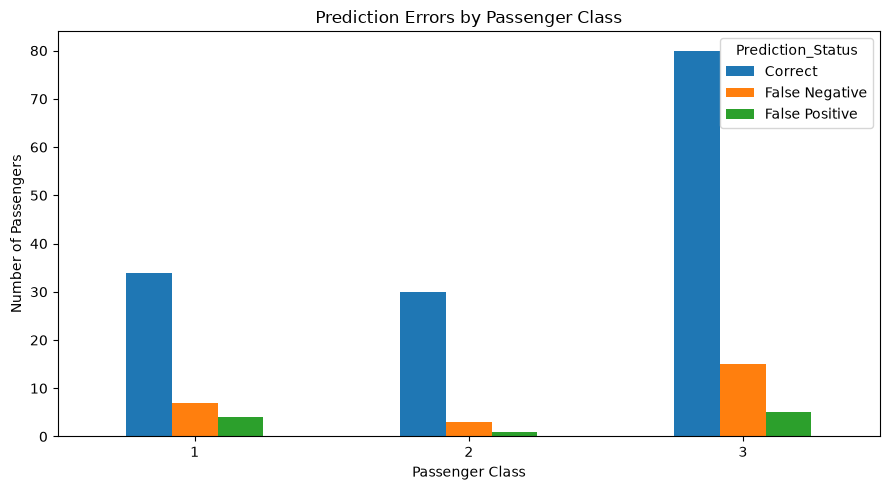

In [21]:
class_errors = error_df.groupby(
    "pclass"
)["Prediction_Status"].value_counts().unstack(fill_value=0)

display(class_errors)

class_errors.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Prediction Errors by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 11. Final Project Conclusion

This project successfully demonstrates an end-to-end tabular machine learning workflow using the Titanic dataset.

### Key Achievements

1. Loaded and analyzed 891 passenger records.
2. Identified missing values and duplicate records.
3. Performed exploratory data analysis with visualizations.
4. Implemented missing value imputation, scaling, and encoding.
5. Created stratified training, validation, and test datasets.
6. Trained and compared Logistic Regression, Decision Tree, and Random Forest.
7. Selected Random Forest using validation F1-score.
8. Evaluated the selected model on unseen test data.
9. Analyzed false positive and false negative predictions.

### Final Test Performance

| Metric | Score |
|---|---:|
| Accuracy | 80.45% |
| Precision | 81.48% |
| Recall | 63.77% |
| F1-score | 71.54% |

### Limitations

- The dataset contains missing values.
- The dataset is relatively small.
- Survivor recall can be improved.
- Historical patterns may not generalize to other datasets.

### Future Improvements

- Hyperparameter tuning
- Feature engineering
- Cross-validation
- Classification threshold optimization
- Further model comparison

### Final Summary

The project provides a reproducible machine learning workflow from data quality analysis to model evaluation and error analysis. It demonstrates practical Python, Pandas, data visualization, and Scikit-learn skills.